In [10]:
import json
from pathlib import Path
import sys

sys.argv = [""]

import numpy as np
import torch
import arviz as az
import matplotlib.pyplot as plt
import xarray
from ICIW_Plots import figure, make_rect_ax, make_square_ax, cm2inch
from scipy.stats.qmc import LatinHypercube, scale

plt.style.use("ICIWstyle")

In [11]:
from HSA_Cam_B_021_pyro import (
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    kl_divergence_between_models,
)
from HSA_Mo_B_008_pyro import kinetics_model

In [12]:
params = {
    "T": (500.0, 600.0),
    "p": (2.0, 20.0),
    "c2h": (0.5, 2.0),
    "f": (10.0, 1000.0),
    "c2i": (0.1, 1.0),
}

# Generate the space filling design points

In [13]:
num_samples = 1000
LHsampler = LatinHypercube(d=len(params))
samples = LHsampler.random(n=num_samples)
samples = scale(
    samples, [v[0] for v in params.values()], [v[1] for v in params.values()]
)

samples = xarray.DataArray(
    data=samples,
    dims=["sample", "parameter"],
    coords={"parameter": list(params.keys())},
)
display(samples)

<xarray.DataArray (sample: 1000, parameter: 5)> Size: 40kB
array([[5.45994249e+02, 1.33085178e+01, 1.85947910e+00, 7.96561307e+02,
        2.67499859e-01],
       [5.98960956e+02, 8.40072798e+00, 1.83436674e+00, 9.75010935e+02,
        5.28507052e-01],
       [5.76931249e+02, 1.31267350e+01, 1.19773102e+00, 7.15169349e+02,
        3.42991951e-01],
       ...,
       [5.73432806e+02, 1.72045822e+01, 6.21106518e-01, 5.90651198e+02,
        8.20620364e-01],
       [5.41707280e+02, 4.22810338e+00, 1.36921710e+00, 2.77533701e+02,
        9.12164050e-01],
       [5.32181902e+02, 1.49024321e+01, 1.41062342e+00, 5.36824485e+02,
        9.77817381e-01]], shape=(1000, 5))
Coordinates:
  * parameter  (parameter) <U3 60B 'T' 'p' 'c2h' 'f' 'c2i'
Dimensions without coordinates: sample

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\density_utils.py:250: RuntimeWarning:

divide by zero encountered in scalar power



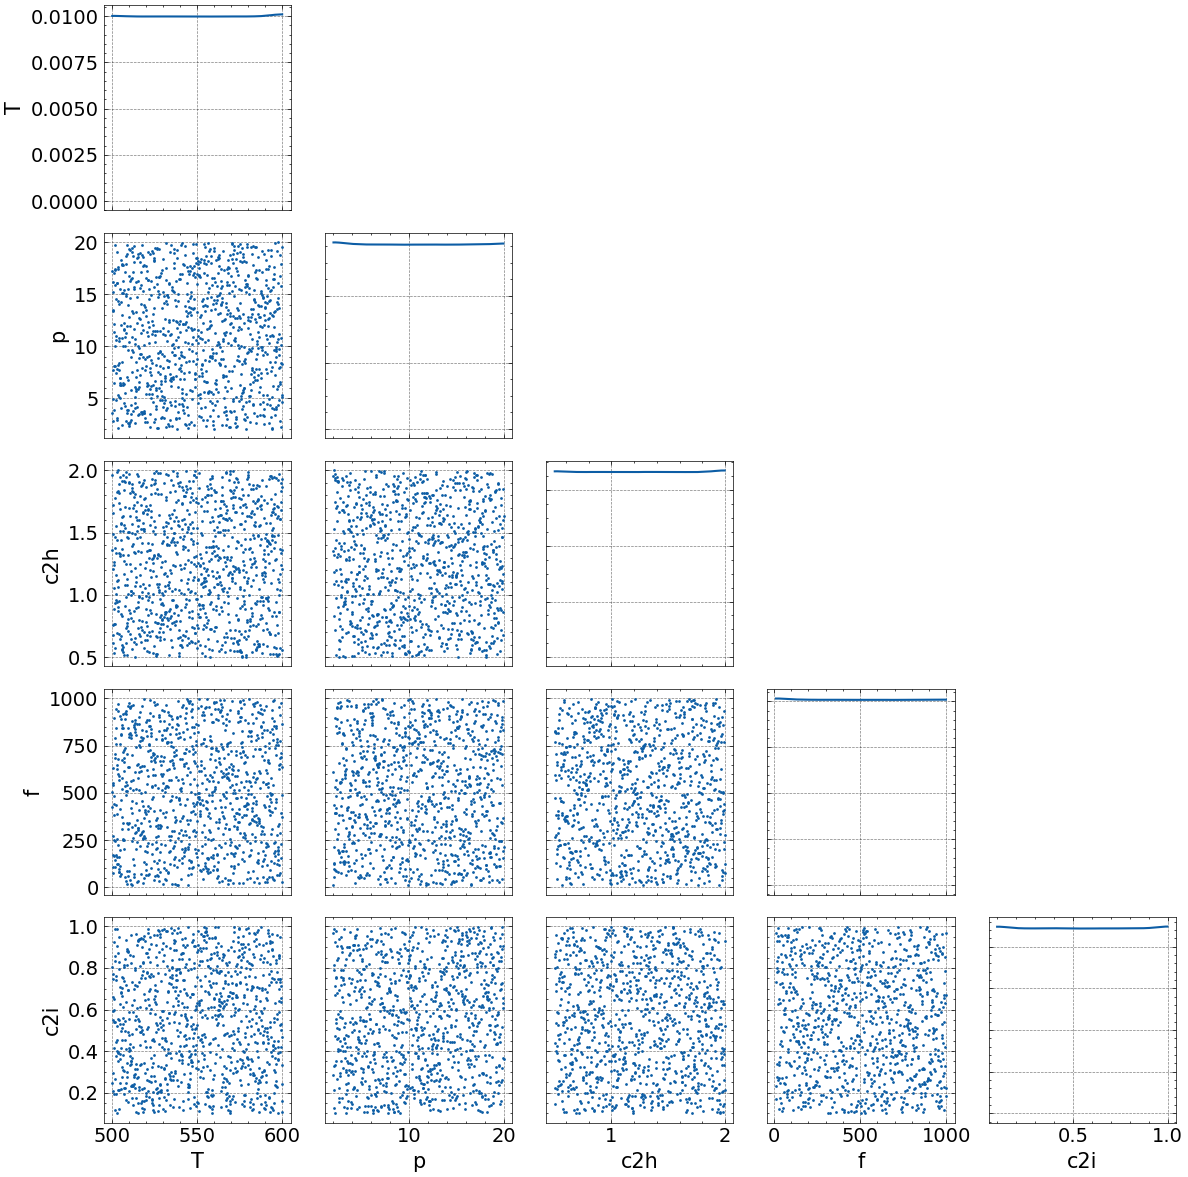

In [14]:
# Convert samples to a format suitable for arviz pair plot
sample_dict = {param: samples.sel(parameter=param).values for param in params.keys()}

az.plot_pair(sample_dict, kind="scatter", marginals=True, figsize=(12, 12))
plt.tight_layout()
plt.show()

Pretty space filling!

## Generate the GT model predictions at these positions

In [26]:
T, p, lat_r = generate_synthetic_data(
    torch.tensor(samples.sel(parameter="T").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="p").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2h").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="f").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2i").values).reshape(-1, 1),
    noise_std=0.0,
)
T, p, obs_r = generate_synthetic_data(
    torch.tensor(samples.sel(parameter="T").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="p").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2h").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="f").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2i").values).reshape(-1, 1),
    noise_std=1e-5,
)

array([[<Axes: title={'center': 'lat_r'}>,
        <Axes: title={'center': 'obs_r'}>]], dtype=object)

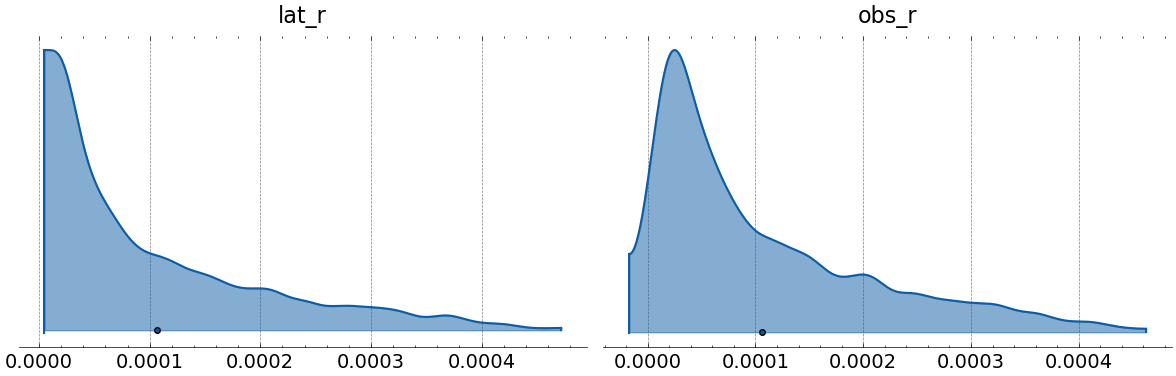

In [27]:
az.plot_density(
    {
        "lat_r": lat_r.numpy().flatten(),
        "obs_r": obs_r.numpy().flatten(),
    },
    figsize=(12, 4),
    hdi_prob=0.999,
    shade=0.5,
)
# ax = plt.gca()
# ax.set_xscale("log")

array([[<Axes: title={'center': 'lat_r'}>]], dtype=object)

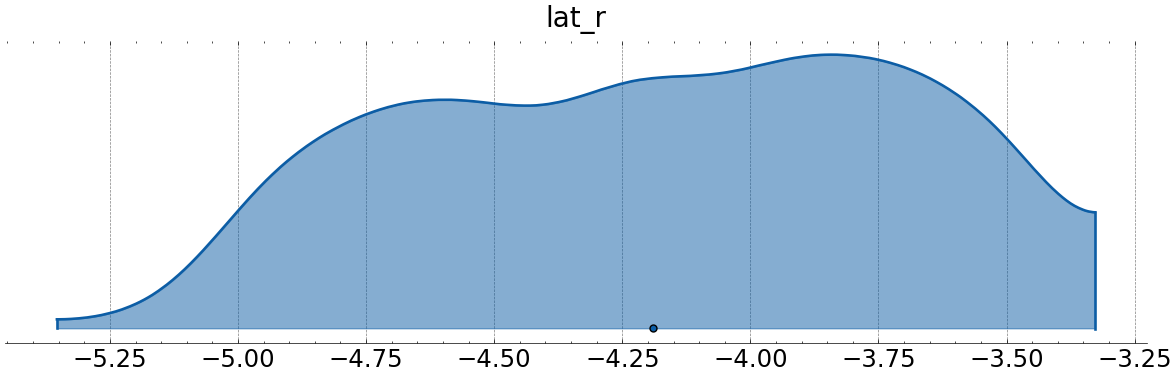

In [38]:
az.plot_density(
    {
        "lat_r": np.log10(lat_r.numpy().flatten()),
    },
    figsize=(12, 4),
    hdi_prob=0.999,
    shade=0.5,
)

In [36]:
data = xarray.Dataset(
    {
        "samples": samples,
        "T": (("sample"), T.numpy().flatten()),
        "p": (("sample", "species"), p.numpy()),
        "latent_r": (("sample"), lat_r.numpy().flatten()),
        "obs_r": (("sample"), obs_r.numpy().flatten()),
    },
    coords={
        "sample": np.arange(num_samples),
        "species": ["CO2", "H2", "H2O", "CH4", "I"],
    },
)
data.attrs["noise"] = "homoscedastic"
data.attrs["sigma"] = 1e-5
display(data)

data.to_netcdf(Path("data/test_data.nc"))

<xarray.Dataset> Size: 112kB
Dimensions:    (parameter: 5, sample: 1000, species: 5)
Coordinates:
  * parameter  (parameter) <U3 60B 'T' 'p' 'c2h' 'f' 'c2i'
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
Data variables:
    samples    (sample, parameter) float64 40kB 546.0 13.31 ... 536.8 0.9778
    T          (sample) float64 8kB 546.0 599.0 576.9 ... 573.4 541.7 532.2
    p          (sample, species) float64 40kB 2.522 1.356 0.0 ... 0.01016 5.576
    latent_r   (sample) float64 8kB 5.491e-05 0.0003088 ... 4.296e-05 4.443e-05
    obs_r      (sample) float64 8kB 5.908e-05 0.0003223 ... 4.16e-05 4.322e-05
Attributes:
    noise:    homoscedastic
    sigma:    1e-05